## NB09 — Comparação dos Modelos e Construção do Ranking de Risco

**Entrada:** `data/load/dataset_ml_model.csv` — 75.471 linhas × 26 colunas  
**Saída:** `data/output/ranking_parcial.csv` — tabela ordenada de risco com scores dos 3 modelos

**Objetivo:**
- Comparar os modelos: sobreposição de anomalias, correlação de scores
- Construir o ranking combinado de risco
- Analisar o perfil das propostas mais anômalas

---
### 0. Imports e Configuração

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from scipy.stats import spearmanr

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')

RANDOM_STATE = 42
CONTAMINATION = 0.01

os.makedirs('data/output', exist_ok=True)
print('Setup OK')

Setup OK


In [2]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs('figuras_tcc', exist_ok=True)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['axes.unicode_minus'] = True

def br(x, casas=0):
    """12345.678 -> '12.345,7' (ponto no milhar, vírgula decimal, sinal de menos correto)."""
    s = f'{round(x, casas) + 0.0:,.{casas}f}'  # '+ 0.0' evita '-0,00'
    return s.replace(',', '#').replace('.', ',').replace('#', '.').replace('-', '\u2212')

def fmt_eixo(ax, eixo='y', casas=0, pct=False):
    """Formato brasileiro nos números de um eixo. pct=True: multiplica por 100 e acrescenta '%'."""
    if pct:
        f = FuncFormatter(lambda v, _: br(v * 100, casas) + '%')
    else:
        f = FuncFormatter(lambda v, _: br(v, casas))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)

---
### 1. Carregamento e Separação de Identificadores

In [3]:
df_full = pd.read_csv('data/load/dataset_ml_model.csv')

print(f'Shape completo: {df_full.shape}')
print(f'\nColunas: {df_full.columns.tolist()}')

Shape completo: (75471, 26)

Colunas: ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem', 'cnpj_forn_norm', 'desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_desde_eleicao', 'pre_eleitoral_180d', 'pos_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao', 'porte', 'descricao_situacao_cadastral']


In [4]:
identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

df_ids  = df_full[identificadores].copy()
df_feat = df_full.drop(columns=identificadores).copy()

feature_cols = df_feat.columns.tolist()

print(f'Features para modelagem ({len(feature_cols)}): {feature_cols}')
print(f'\nShape features: {df_feat.shape}')
print(f'NaN nas features: {df_feat.isnull().sum().sum()}')

Features para modelagem (21): ['desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_desde_eleicao', 'pre_eleitoral_180d', 'pos_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao', 'porte', 'descricao_situacao_cadastral']

Shape features: (75471, 21)
NaN nas features: 0


---
### 2. Treinamento dos Modelos

Reprodução fiel dos hiperparâmetros definidos no NB08.

#### 2.1 Isolation Forest

In [5]:
print('Treinando Isolation Forest...')

iso_forest = IsolationForest(
    n_estimators=100,
    contamination=CONTAMINATION,
    max_samples=256,
    random_state=RANDOM_STATE
)
iso_forest.fit(df_feat[feature_cols])

df_feat['if_score']  = iso_forest.decision_function(df_feat[feature_cols])
df_feat['if_label']  = iso_forest.predict(df_feat[feature_cols])  # 1=normal, -1=anomalia

n_if = (df_feat['if_label'] == -1).sum()
print(f'IF → {n_if} anomalias ({n_if/len(df_feat):.1%})')

Treinando Isolation Forest...


IF → 743 anomalias (1.0%)


#### 2.2 Local Outlier Factor

O LOF compara densidades locais a partir de **distâncias entre registros**, então:

- **Escala:** as features são padronizadas com `StandardScaler`, o mesmo tratamento do One-Class SVM (uma única matriz padronizada alimenta os dois modelos baseados em distância).
  O Isolation Forest não precisa de padronização, porque seus cortes são feitos variável a variável. A comparação com o LOF sem padronização e com `RobustScaler` está na seção 2.4.
- **Duplicatas:** vetores idênticos têm distância zero entre si, e com mais de `n_neighbors` cópias a densidade local tende ao infinito (escores de 10¹⁰ ou mais, que são efeito numérico e não anomalias).
  Por isso o LOF é ajustado **apenas nos vetores únicos**; cada proposta herda o escore do seu vetor e a **contagem de cópias** é guardada em `lof_n_copias`.
  O limiar de 1% é aplicado sobre as **propostas** (linhas), como nos demais modelos. Contagem das duplicatas e testes de reprodutibilidade estão na seção 2.5.

In [6]:
print('Treinando Local Outlier Factor...')

# LOF depende de distâncias: padroniza as features (StandardScaler, a mesma entrada do One-Class SVM).
# O Isolation Forest não precisa de padronização. Comparação com/sem padronização e com RobustScaler: seção 2.4.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_feat[feature_cols])


def lof_vetores_unicos(Z, n_neighbors=50, contamination=CONTAMINATION, algorithm='auto'):
    """LOF ajustado só nos vetores únicos. Vetores idênticos têm distância zero e, com mais de n_neighbors
    cópias, a densidade local explode. Cada linha herda o escore do seu vetor; o limiar de `contamination`
    é aplicado sobre as LINHAS (propostas). Devolve: escore, rótulo (-1 = anomalia), nº de cópias e o modelo."""
    Zu, inverso, copias = np.unique(Z, axis=0, return_inverse=True, return_counts=True)
    inverso = np.asarray(inverso).ravel()
    modelo = LocalOutlierFactor(n_neighbors=n_neighbors, algorithm=algorithm).fit(Zu)
    escore = (-modelo.negative_outlier_factor_)[inverso]
    rotulo = np.where(escore >= np.quantile(escore, 1 - contamination), -1, 1)
    return escore, rotulo, copias[inverso], modelo


lof_scores, lof_preds, lof_copias, lof = lof_vetores_unicos(X_scaled)

df_feat['lof_score'] = lof_scores
df_feat['lof_label'] = lof_preds   # 1=normal, -1=anomalia
df_feat['lof_n_copias'] = lof_copias

n_lof = (df_feat['lof_label'] == -1).sum()
print(f'LOF → {n_lof} anomalias ({n_lof/len(df_feat):.1%}) | vetores únicos: {len(np.unique(X_scaled, axis=0))} de {len(X_scaled)} linhas')


Treinando Local Outlier Factor...


LOF → 755 anomalias (1.0%) | vetores únicos: 56515 de 75471 linhas


#### 2.3 One-Class SVM (com StandardScaler)

**Como interpretar `nu`.** O parâmetro `nu` **não é** a proporção de anomalias que o modelo vai rotular. Ele é (Schölkopf et al., 2001) um **limite superior** para a fração de pontos de treino que ficam
fora da fronteira e um **limite inferior** para a fração de vetores de suporte. Por isso `nu = 0,01` pode resultar em mais de 1% de propostas com função de decisão negativa.
Com muitas propostas idênticas isso acontece de fato: todas as cópias de um vetor têm a mesma função de decisão, então, se o vetor fica a menos da tolerância do solucionador da fronteira,
todas as cópias saem negativas de uma vez. A seção 2.6 mede isso (na rodada anterior à correção das variáveis o OCSVM sinalizou 2,1% das propostas).

In [7]:
# usa a mesma matriz padronizada (X_scaled) calculada para o LOF na seção 2.2

print('Treinando One-Class SVM...')
ocsvm = OneClassSVM(kernel='rbf', nu=CONTAMINATION, gamma='scale')
ocsvm.fit(X_scaled)

df_feat['ocsvm_score'] = ocsvm.decision_function(X_scaled)
df_feat['ocsvm_label'] = ocsvm.predict(X_scaled)  # 1=normal, -1=anomalia

n_ocsvm = (df_feat['ocsvm_label'] == -1).sum()
print(f'OCSVM → {n_ocsvm} anomalias ({n_ocsvm/len(df_feat):.1%})')

Treinando One-Class SVM...


OCSVM → 816 anomalias (1.1%)


#### 2.4 Sensibilidade do LOF ao escalonamento

Compara os conjuntos sinalizados pelo LOF **sem padronização**, com **`StandardScaler`** (adotado) e com **`RobustScaler`**, todos ajustados só nos vetores únicos (seção 2.2).
O LOF é determinístico, então a tabela é reprodutível e fica salva em `data/output/comparacao_escalonamento_lof.csv`.
A contaminação fixa (1%) faz os três tratamentos sinalizarem o mesmo número de propostas; o que muda é **quais**.

O que a tabela mostra:
- **Sem padronização**, uma única variável concentra quase toda a variância bruta (`dias_desde_eleicao`) e a vizinhança de 50 registros é decidida por ela e pela idade da empresa,
  enquanto modalidade, origem do fornecedor e porte quase não pesam (veja as colunas de vizinhos com o mesmo perfil).
- **Padronizar** faz a vizinhança respeitar o perfil dos registros, e o conjunto sinalizado muda quase por completo (Jaccard baixo contra o tratamento sem padronização).
- **`RobustScaler` não trouxe ganho** sobre o `StandardScaler`: os conjuntos são parecidos e o `RobustScaler` deixa sem escala as colunas com IQR = 0 (inclusive `n_propostas_item`, que chega a 42).
  Também não há cauda tão pesada a ponto de o desvio-padrão ser inadequado (por exemplo, o desvio-padrão da idade da empresa é menor que o IQR).

**Decisão:** `StandardScaler`, o mesmo tratamento do One-Class SVM.

In [8]:
from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import NearestNeighbors

bruto = df_feat[feature_cols].astype(float)

# (a) Amplitude das variáveis: o que o LOF "enxerga" sem padronização
amp = pd.DataFrame({'mínimo': bruto.min(), 'máximo': bruto.max(), 'desvio-padrão': bruto.std(),
                    'IQR': bruto.quantile(.75) - bruto.quantile(.25),
                    '% da variância bruta': bruto.var() / bruto.var().sum() * 100})
print('Variáveis com maior participação na variância bruta:')
print(amp.sort_values('% da variância bruta', ascending=False).head(4).round(3).to_string())
print(f'\nColunas com IQR = 0 (o RobustScaler não as escala): {[c for c in feature_cols if amp.loc[c, "IQR"] == 0]}')

# (b) LOF nos três tratamentos (só vetores únicos)
entradas = {
    'Sem padronização':         bruto.to_numpy(),
    'StandardScaler (adotado)': X_scaled,
    'RobustScaler':             RobustScaler().fit_transform(bruto),
}
lof_var = {}
for nome, Z in entradas.items():
    escore, rotulo, _, _ = lof_vetores_unicos(Z)     # mesmo tratamento de duplicatas da seção 2.2
    lof_var[nome] = (escore, rotulo == -1)

ref_score, ref_flag = lof_var['StandardScaler (adotado)']
if_flag = (df_feat['if_label'] == -1).to_numpy()
oc_flag = (df_feat['ocsvm_label'] == -1).to_numpy()
sem_cadastro = (df_feat['porte'] == 0).to_numpy()

# (c) A vizinhança respeita o perfil? % dos 50 vizinhos com o mesmo valor da consulta (2.000 consultas, semente fixa)
q = np.random.RandomState(RANDOM_STATE).choice(len(bruto), 2000, replace=False)
perfil = ['modalidade_Dispensa', 'fornecedor_fora_pe', 'porte']

linhas = []
for nome, Z in entradas.items():
    score, flag = lof_var[nome]
    viz = NearestNeighbors(n_neighbors=51).fit(Z).kneighbors(Z[q], return_distance=False)[:, 1:]
    linha = {'Tratamento': nome, 'Sinalizadas': int(flag.sum()),
             'Jaccard vs adotado': (flag & ref_flag).sum() / (flag | ref_flag).sum(),
             'Spearman dos escores vs adotado': spearmanr(score, ref_score)[0],
             '% sem cadastro': sem_cadastro[flag].mean() * 100,
             'Também no IF': int((flag & if_flag).sum()), 'Também no OCSVM': int((flag & oc_flag).sum())}
    for c in perfil:
        v = bruto[c].to_numpy()
        linha[f'% vizinhos c/ mesma {c}'] = (v[viz] == v[q][:, None]).mean() * 100
    linhas.append(linha)

comp_lof = pd.DataFrame(linhas).set_index('Tratamento')
print('\n=== LOF: sem padronização × StandardScaler × RobustScaler ===')
print(comp_lof.round(2).T.to_string())
print(f'\n(base: {sem_cadastro.mean()*100:.1f}% das linhas sem cadastro)')

comp_lof.round(4).to_csv('data/output/comparacao_escalonamento_lof.csv')
print('Salvo em data/output/comparacao_escalonamento_lof.csv')


Variáveis com maior participação na variância bruta:
                    mínimo   máximo  desvio-padrão      IQR  % da variância bruta
dias_desde_eleicao  -641.0   85.000        173.147  274.000                99.494
idade_empresa_anos     0.0  116.331         11.465   14.418                 0.436
mes                    1.0   12.000          3.103    5.000                 0.032
n_propostas_item       1.0   42.000          2.266    0.000                 0.017

Colunas com IQR = 0 (o RobustScaler não as escala): ['n_propostas_item', 'fornecedor_unico', 'pos_eleitoral_180d', 'tipo_fornecedor', 'empresa_nova', 'opcao_pelo_mei', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'descricao_situacao_cadastral']



=== LOF: sem padronização × StandardScaler × RobustScaler ===
Tratamento                               Sem padronização  StandardScaler (adotado)  RobustScaler
Sinalizadas                                        755.00                    755.00        755.00
Jaccard vs adotado                                   0.23                      1.00          0.69
Spearman dos escores vs adotado                      0.32                      1.00          0.74
% sem cadastro                                      33.11                     23.44         28.87
Também no IF                                         0.00                      0.00          0.00
Também no OCSVM                                      2.00                     18.00         13.00
% vizinhos c/ mesma modalidade_Dispensa             86.13                     99.79         99.50
% vizinhos c/ mesma fornecedor_fora_pe              80.16                     98.67         97.72
% vizinhos c/ mesma porte                           74.

#### 2.5 Duplicatas e reprodutibilidade do LOF

**Duplicatas.** Contagem dos vetores de atributos idênticos e comparação do LOF ajustado em todas as linhas com o ajustado só nos vetores únicos (adotado). Com mais de `n_neighbors` = 50 cópias de um mesmo vetor,
a distância ao 50º vizinho é zero e a densidade local tende ao infinito: os escores de 10¹⁰ a 10¹⁴ do LOF nas execuções anteriores eram efeito numérico das duplicatas, não anomalias de comportamento.

**Reprodutibilidade.** O LOF do scikit-learn é determinístico: os mesmos dados, parâmetros e ordem dão o mesmo resultado (repetir a execução ou mudar `n_jobs` não altera nada). Mas, **com duplicatas**, o resultado depende da ordem das linhas
e do algoritmo de vizinhos (`brute`, `kd_tree`...), porque os empates entre cópias idênticas são desfeitos pela ordem. Com **vetores únicos** isso desaparece. A tabela abaixo mostra as duas situações.

**Origem das contagens diferentes em versões anteriores** (reproduzidas sobre a base original, commit `33c92fd`, LOF sem padronização): **755** com `n_neighbors=50` e as 20 variáveis (NB09);
**760** com `n_neighbors=20` (primeira versão do NB08); **763** quando as colunas `anomaly_score` e `anomaly` do Isolation Forest entraram como variáveis do LOF (estado residual de uma célula reexecutada do NB08, corrigido: `feature_cols` agora é fixado antes do IF).
Não foram diferenças do arquivo de dados, que foi commitado uma única vez antes das correções.

In [9]:
# (a) Quantas duplicatas?
grp = df_feat.groupby(feature_cols, sort=False).ngroup()
por_vetor = grp.value_counts()
copias_linha = grp.map(por_vetor)
repetidos = por_vetor[por_vetor >= 2]
resumo_dup = pd.Series({
    'Propostas (linhas)': len(df_feat),
    'Vetores distintos': int(por_vetor.size),
    'Propostas em vetores com 2 ou mais cópias': int((copias_linha >= 2).sum()),
    '% das propostas': round((copias_linha >= 2).mean() * 100, 1),
    'Propostas redundantes (cópias além da primeira)': int(len(df_feat) - por_vetor.size),
    'Vetores repetidos (2 ou mais cópias)': int(len(repetidos)),
    'Cópias por vetor repetido — mediana': float(repetidos.median()),
    'Cópias por vetor repetido — máximo': int(por_vetor.max()),
    'Vetores com mais de 50 cópias (> n_neighbors)': int((por_vetor > 50).sum()),
    'Propostas nesses vetores': int((copias_linha > 50).sum()),
})
print('=== Duplicatas nos vetores de atributos ===')
print(resumo_dup.to_string())

# (b) LOF em todas as linhas × só vetores únicos (mesma matriz padronizada)
def lof_todas_as_linhas(Z, algorithm='auto'):
    m_ = LocalOutlierFactor(n_neighbors=50, contamination=CONTAMINATION, algorithm=algorithm)
    rot = m_.fit_predict(Z)
    return -m_.negative_outlier_factor_, rot == -1

def lof_unicos(Z, algorithm='auto'):
    esc, rot, _, _ = lof_vetores_unicos(Z, algorithm=algorithm)
    return esc, rot == -1

def jac(a, b): return (a & b).sum() / (a | b).sum()
sem_cad = (df_feat['porte'] == 0).to_numpy()
rot_cad = f'% sem cadastro (base: {sem_cad.mean() * 100:.1f}%)'
esc_t, flag_t = lof_todas_as_linhas(X_scaled)
esc_u, flag_u = lof_unicos(X_scaled)

comp_dup = pd.DataFrame({
    'LOF em todas as linhas': {'Sinalizadas': int(flag_t.sum()), rot_cad: round(sem_cad[flag_t].mean() * 100, 1),
                               'Escore p99': float(np.quantile(esc_t, .99)), 'Escore máximo': float(esc_t.max()), 'Propostas com escore > 10³': int((esc_t > 1e3).sum())},
    'LOF em vetores únicos (adotado)': {'Sinalizadas': int(flag_u.sum()), rot_cad: round(sem_cad[flag_u].mean() * 100, 1),
                               'Escore p99': float(np.quantile(esc_u, .99)), 'Escore máximo': float(esc_u.max()), 'Propostas com escore > 10³': int((esc_u > 1e3).sum())},
})
print('\n=== LOF: todas as linhas × vetores únicos ===')
print(comp_dup.to_string(float_format=lambda v: f'{v:,.4g}'))
print(f'Jaccard entre os dois conjuntos sinalizados: {jac(flag_t, flag_u):.3f}')

# (c) Reprodutibilidade: mudar a ordem das linhas e o algoritmo de vizinhos
def embaralhado(fn, Z, semente):
    p = np.random.RandomState(semente).permutation(len(Z))
    s, f = fn(Z[p]); s0, f0 = np.empty_like(s), np.empty_like(f); s0[p] = s; f0[p] = f
    return s0, f0

testes = {
    'ordem original':            lambda fn: fn(X_scaled),
    'ordem embaralhada (sem. 1)': lambda fn: embaralhado(fn, X_scaled, 1),
    'ordem embaralhada (sem. 2)': lambda fn: embaralhado(fn, X_scaled, 2),
    "algorithm='kd_tree'":        lambda fn: fn(X_scaled, algorithm='kd_tree'),
}
repro = []
for modo, fn in [('todas as linhas', lof_todas_as_linhas), ('vetores únicos', lof_unicos)]:
    _, flag_base = fn(X_scaled)
    for nome_t, exec_t in testes.items():
        _, flag = exec_t(fn)
        repro.append({'LOF': modo, 'variação': nome_t, 'sinalizadas': int(flag.sum()),
                      'Jaccard vs ordem original': round(jac(flag, flag_base), 3), 'idêntico': bool((flag == flag_base).all())})
repro = pd.DataFrame(repro)
print('\n=== Reprodutibilidade do LOF (padronizado, n_neighbors=50) ===')
print(repro.to_string(index=False))

resumo_dup.to_frame('valor').to_csv('data/output/duplicatas_vetores.csv')
repro.to_csv('data/output/reprodutibilidade_lof.csv', index=False)
print('\nSalvos: data/output/duplicatas_vetores.csv e data/output/reprodutibilidade_lof.csv')


=== Duplicatas nos vetores de atributos ===
Propostas (linhas)                                 75471.0
Vetores distintos                                  56515.0
Propostas em vetores com 2 ou mais cópias          23213.0
% das propostas                                       30.8
Propostas redundantes (cópias além da primeira)    18956.0
Vetores repetidos (2 ou mais cópias)                4257.0
Cópias por vetor repetido — mediana                    2.0
Cópias por vetor repetido — máximo                   500.0
Vetores com mais de 50 cópias (> n_neighbors)         40.0
Propostas nesses vetores                            5766.0



=== LOF: todas as linhas × vetores únicos ===
                              LOF em todas as linhas  LOF em vetores únicos (adotado)
Sinalizadas                                      755                              755
% sem cadastro (base: 24.8%)                    68.6                             23.4
Escore p99                                 1.568e+09                            7.719
Escore máximo                              3.355e+10                        7.781e+05
Propostas com escore > 10³                     1,640                              194
Jaccard entre os dois conjuntos sinalizados: 0.015



=== Reprodutibilidade do LOF (padronizado, n_neighbors=50) ===
            LOF                   variação  sinalizadas  Jaccard vs ordem original  idêntico
todas as linhas             ordem original          755                      1.000      True
todas as linhas ordem embaralhada (sem. 1)          746                      0.985     False
todas as linhas ordem embaralhada (sem. 2)          746                      0.985     False
todas as linhas        algorithm='kd_tree'          750                      0.980     False
 vetores únicos             ordem original          755                      1.000      True
 vetores únicos ordem embaralhada (sem. 1)          755                      1.000      True
 vetores únicos ordem embaralhada (sem. 2)          755                      1.000      True
 vetores únicos        algorithm='kd_tree'          755                      1.000      True

Salvos: data/output/duplicatas_vetores.csv e data/output/reprodutibilidade_lof.csv


#### 2.6 Por que `nu = 0,01` não sinaliza exatamente 1%? (diagnóstico do OCSVM)

A orientadora levantou duas hipóteses para a proporção acima de 1%: pontos concentrados muito perto da fronteira por causa de **duplicatas** e a **tolerância numérica** do solucionador. A tabela abaixo as testa.

**Resultado:**
- O treino **converge** (`fit_status_ = 0`) e as propriedades de `nu` valem onde deveriam: os vetores de suporte são pelo menos `nu × N` e os que estão no limite superior são no máximo `nu × N`.
- O excesso vem da **classificação**: os pontos com função de decisão negativa **dentro da tolerância do solucionador** (`|f| < tol`) pertencem a poucos vetores distintos, cada um com muitas cópias, que são rotulados em bloco.
  Com o limiar `f < -tol` a fração volta para menos de 1%.
- **Tolerância:** apertá-la (`tol = 1e-5`) não elimina o efeito nem estabiliza a contagem.
- **Ordem das linhas:** como o problema dual com cópias idênticas não tem solução única, **embaralhar as linhas muda a contagem e o conjunto sinalizado**. Os rótulos do OCSVM devem ser lidos como uma realização dentro de uma faixa, não como um valor exato.
- Ajustado **só nos vetores únicos**, a fração de *vetores* sinalizados fica em torno de `nu` (a propriedade vale por vetor distinto), mas as *propostas* sinalizadas são mais, porque cada vetor carrega suas cópias.

**Mesmo diagnóstico sobre a base original da monografia** (commit `33c92fd`, reproduzido fora do notebook): 1.586 propostas com função de decisão negativa (2,08%, contra `nu × N` = 762); 1.069 delas (67%) a menos de `1e-3` da fronteira, em apenas 84 vetores distintos
(mediana de 48 cópias, máximo de 484); com o limiar `f < -1e-3`, 517 (0,68%); ajustado nos 56.679 vetores únicos, 573 vetores (1,01%); tolerâncias de `1e-4` a `1e-6` dão 1.342 a 1.542, e embaralhar a ordem, 999 a 1.586.

In [10]:
from sklearn.svm import OneClassSVM

f = df_feat['ocsvm_score'].to_numpy()          # função de decisão do OCSVM (negativa = fora da fronteira)
N = len(f)
nu_N = CONTAMINATION * N
tol = ocsvm.tol
coef = np.abs(ocsvm.dual_coef_).ravel()
sv_limite = int((coef >= coef.max() * (1 - 1e-6)).sum())      # vetores de suporte no limite superior (os "fora da fronteira" do problema dual)
neg = f < 0
perto = neg & (f > -tol)                                      # negativos dentro da tolerância do solucionador

# sensibilidade: tolerância, ordem das linhas e vetores únicos
def ajusta(Z, **kw):
    return OneClassSVM(kernel='rbf', nu=CONTAMINATION, gamma='scale', **kw).fit(Z)

def decisao_embaralhada(semente):
    p = np.random.RandomState(semente).permutation(N)
    m_ = ajusta(X_scaled[p]); fp = m_.decision_function(X_scaled[p]); f0 = np.empty_like(fp); f0[p] = fp
    return f0

f_tol = ajusta(X_scaled, tol=1e-5).decision_function(X_scaled)
f_ord = [decisao_embaralhada(s) for s in (1, 2)]
Zu, inv = np.unique(X_scaled, axis=0, return_inverse=True); inv = np.asarray(inv).ravel()
f_u = ajusta(Zu).decision_function(Zu)

diag = pd.Series({
    'Propostas (N) / vetores distintos': f'{N} / {len(Zu)}',
    'nu × N (limite teórico de pontos fora da fronteira)': round(nu_N, 1),
    'Vetores de suporte (esperado >= nu × N)': int(len(ocsvm.support_)),
    'Vetores de suporte no limite superior (esperado <= nu × N)': sv_limite,
    'Convergência (fit_status_: 0 = convergiu) / iterações': f'{ocsvm.fit_status_} / {int(np.max(ocsvm.n_iter_))}',
    'Tolerância do solucionador (tol)': tol,
    'Propostas com função de decisão < 0 (as sinalizadas)': f'{int(neg.sum())} ({neg.mean() * 100:.2f}%)',
    '   dessas, a menos de tol da fronteira': f'{int(perto.sum())} ({perto.sum() / neg.sum() * 100:.0f}% das sinalizadas)',
    '   vetores distintos entre elas': int(grp[perto].nunique()),
    '   cópias por vetor (mediana / máximo)': f'{int(np.median(copias_linha[perto]))} / {int(copias_linha[perto].max())}' if perto.any() else '0 / 0',
    'Sinalizadas com o limiar f < -tol': f'{int((f < -tol).sum())} ({(f < -tol).mean() * 100:.2f}%)',
    'Sinalizadas com tol = 1e-5': f'{int((f_tol < 0).sum())} ({(f_tol < 0).mean() * 100:.2f}%)',
    'Sinalizadas embaralhando as linhas (sementes 1 e 2)': ' e '.join(f'{int((x < 0).sum())} ({(x < 0).mean() * 100:.2f}%)' for x in f_ord),
    'Ajustado nos vetores únicos: vetores com f < 0': f'{int((f_u < 0).sum())} ({(f_u < 0).mean() * 100:.2f}% dos vetores)',
    'Ajustado nos vetores únicos: propostas com f < 0': f'{int((f_u[inv] < 0).sum())} ({(f_u[inv] < 0).mean() * 100:.2f}%)',
})
print('=== OCSVM: nu = %g e a proporção sinalizada ===' % CONTAMINATION)
print(diag.to_string())
diag.to_frame('valor').to_csv('data/output/diagnostico_ocsvm.csv')
print('\nSalvo em data/output/diagnostico_ocsvm.csv')


=== OCSVM: nu = 0.01 e a proporção sinalizada ===
Propostas (N) / vetores distintos                                         75471 / 56515
nu × N (limite teórico de pontos fora da fronteira)                               754.7
Vetores de suporte (esperado >= nu × N)                                             867
Vetores de suporte no limite superior (esperado <= nu × N)                          659
Convergência (fit_status_: 0 = convergiu) / iterações                          0 / 1193
Tolerância do solucionador (tol)                                                  0.001
Propostas com função de decisão < 0 (as sinalizadas)                        816 (1.08%)
   dessas, a menos de tol da fronteira                        307 (38% das sinalizadas)
   vetores distintos entre elas                                                      90
   cópias por vetor (mediana / máximo)                                          22 / 77
Sinalizadas com o limiar f < -tol                                     

---
### 3. Tabela Comparativa Inicial

In [11]:
comparativo = pd.DataFrame({
    'Modelo': ['Isolation Forest', 'Local Outlier Factor', 'One-Class SVM'],
    'Hiperparâmetros': [
        'n_estimators=100, max_samples=256, contamination=0.01',
        'n_neighbors=50, contamination=0.01 + StandardScaler, só vetores únicos',
        'kernel=rbf, nu=0.01, gamma=scale + StandardScaler'
    ],
    'Anomalias Detectadas': [
        (df_feat['if_label'] == -1).sum(),
        (df_feat['lof_label'] == -1).sum(),
        (df_feat['ocsvm_label'] == -1).sum()
    ],
    '% da Base': [
        f"{(df_feat['if_label'] == -1).mean():.2%}",
        f"{(df_feat['lof_label'] == -1).mean():.2%}",
        f"{(df_feat['ocsvm_label'] == -1).mean():.2%}"
    ]
})

print('=== Tabela Comparativa dos Modelos ===')
print(comparativo.to_string(index=False))

=== Tabela Comparativa dos Modelos ===
              Modelo                                                        Hiperparâmetros  Anomalias Detectadas % da Base
    Isolation Forest                  n_estimators=100, max_samples=256, contamination=0.01                   743     0.98%
Local Outlier Factor n_neighbors=50, contamination=0.01 + StandardScaler, só vetores únicos                   755     1.00%
       One-Class SVM                      kernel=rbf, nu=0.01, gamma=scale + StandardScaler                   816     1.08%


---
### 4. Análise de Sobreposição (Overlap)

Quantas propostas são sinalizadas por 1, 2 ou 3 modelos simultaneamente?

In [12]:
set_if    = set(df_feat[df_feat['if_label']    == -1].index)
set_lof   = set(df_feat[df_feat['lof_label']   == -1].index)
set_ocsvm = set(df_feat[df_feat['ocsvm_label'] == -1].index)

todos_3    = set_if & set_lof & set_ocsvm
if_lof     = (set_if & set_lof)    - todos_3
if_ocsvm   = (set_if & set_ocsvm)  - todos_3
lof_ocsvm  = (set_lof & set_ocsvm) - todos_3
so_if      = set_if    - set_lof - set_ocsvm
so_lof     = set_lof   - set_if  - set_ocsvm
so_ocsvm   = set_ocsvm - set_if  - set_lof

print('=== Sobreposição entre Modelos ===')
print(f'Flagados pelos 3 modelos:       {len(todos_3):>5} ({len(todos_3)/len(df_feat):.3%})')
print(f'Apenas IF + LOF:                {len(if_lof):>5} ({len(if_lof)/len(df_feat):.3%})')
print(f'Apenas IF + OCSVM:              {len(if_ocsvm):>5} ({len(if_ocsvm)/len(df_feat):.3%})')
print(f'Apenas LOF + OCSVM:             {len(lof_ocsvm):>5} ({len(lof_ocsvm)/len(df_feat):.3%})')
print(f'Apenas IF:                      {len(so_if):>5} ({len(so_if)/len(df_feat):.3%})')
print(f'Apenas LOF:                     {len(so_lof):>5} ({len(so_lof)/len(df_feat):.3%})')
print(f'Apenas OCSVM:                   {len(so_ocsvm):>5} ({len(so_ocsvm)/len(df_feat):.3%})')
print(f'\nUnião total (≥1 modelo):        {len(set_if|set_lof|set_ocsvm):>5} ({len(set_if|set_lof|set_ocsvm)/len(df_feat):.3%})')

=== Sobreposição entre Modelos ===
Flagados pelos 3 modelos:           0 (0.000%)
Apenas IF + LOF:                    0 (0.000%)
Apenas IF + OCSVM:                288 (0.382%)
Apenas LOF + OCSVM:                18 (0.024%)
Apenas IF:                        455 (0.603%)
Apenas LOF:                       737 (0.977%)
Apenas OCSVM:                     510 (0.676%)

União total (≥1 modelo):         2008 (2.661%)


In [13]:
df_feat['votos'] = (
    (df_feat['if_label']    == -1).astype(int) +
    (df_feat['lof_label']   == -1).astype(int) +
    (df_feat['ocsvm_label'] == -1).astype(int)
)

votos_dist = df_feat['votos'].value_counts().sort_index().reindex([0, 1, 2, 3], fill_value=0)   # níveis ausentes (ex.: 3 votos) contam como 0
print('=== Distribuição de Votos ===')
for v, n in votos_dist.items():
    label = {
        0: 'Normal (nenhum modelo)',
        1: 'Baixo risco (1 modelo)',
        2: 'Médio risco (2 modelos)',
        3: 'Alto risco (3 modelos)'
    }[v]
    print(f'  {v} voto(s) — {label}: {n:>6} ({n/len(df_feat):.2%})')

=== Distribuição de Votos ===
  0 voto(s) — Normal (nenhum modelo):  73463 (97.34%)
  1 voto(s) — Baixo risco (1 modelo):   1702 (2.26%)
  2 voto(s) — Médio risco (2 modelos):    306 (0.41%)
  3 voto(s) — Alto risco (3 modelos):      0 (0.00%)


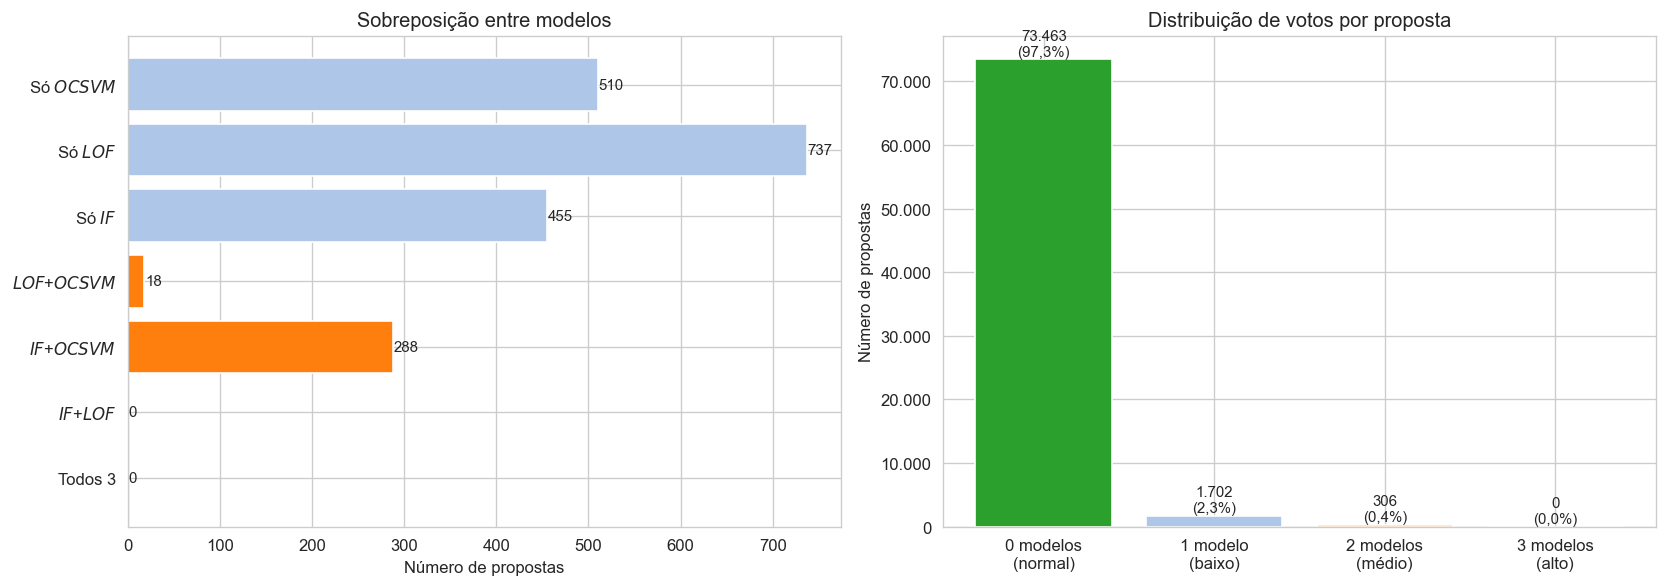

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

IF_, LOF_, OCSVM_ = r'$\mathit{IF}$', r'$\mathit{LOF}$', r'$\mathit{OCSVM}$'
labels_overlap = [
    'Todos 3', f'{IF_}+{LOF_}', f'{IF_}+{OCSVM_}', f'{LOF_}+{OCSVM_}',
    f'Só {IF_}', f'Só {LOF_}', f'Só {OCSVM_}'
]
counts_overlap = [
    len(todos_3), len(if_lof), len(if_ocsvm), len(lof_ocsvm),
    len(so_if), len(so_lof), len(so_ocsvm)
]
colors = ['#d62728', '#ff7f0e', '#ff7f0e', '#ff7f0e', '#aec7e8', '#aec7e8', '#aec7e8']
axes[0].barh(labels_overlap, counts_overlap, color=colors)
axes[0].set_xlabel('Número de propostas')
axes[0].set_title('Sobreposição entre modelos')
for i, v in enumerate(counts_overlap):
    axes[0].text(v + 1, i, br(v, 0), va='center', fontsize=9)
fmt_eixo(axes[0], 'x', 0)

votos_colors = ['#2ca02c', '#aec7e8', '#ff7f0e', '#d62728']
votos_labels = ['0 modelos\n(normal)', '1 modelo\n(baixo)', '2 modelos\n(médio)', '3 modelos\n(alto)']
bars = axes[1].bar(votos_labels, votos_dist.values, color=votos_colors)
axes[1].set_title('Distribuição de votos por proposta')
axes[1].set_ylabel('Número de propostas')
for bar, val in zip(bars, votos_dist.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{br(val, 0)}\n({br(val/len(df_feat)*100, 1)}%)',
                 ha='center', va='bottom', fontsize=9)
fmt_eixo(axes[1], 'y', 0)

plt.tight_layout()
plt.savefig('data/output/fig_sobreposicao_modelos.png', bbox_inches='tight')
plt.show()

---
### 5. Construção do Ranking Combinado

**Critérios de ordenação:**
1. **Votos** (primário): quantos dos 3 modelos sinalizaram a proposta como anômala.
2. **Escore combinado** $c_i$ (desempate): média simples dos três escores normalizados, definida abaixo.

**Escores orientados** (maior = mais anômalo). Para a proposta $i$:

$$ s^{IF}_i = -f^{IF}_i, \qquad s^{LOF}_i = -\texttt{negative\_outlier\_factor\_}_i, \qquad s^{OCSVM}_i = -f^{OCSVM}_i $$

em que $f$ é a `decision_function` do Isolation Forest e do One-Class SVM (positiva para pontos normais, negativa para anomalias). O atributo `negative_outlier_factor_` do scikit-learn é o **oposto do LOF**
(vem com sinal negativo); por isso se troca o sinal para recuperar o LOF, que vale cerca de 1 para pontos normais e cresce com a anomalia.

**Normalização.** Com $\mathrm{mm}(x)=\dfrac{x-\min x}{\max x-\min x}$ (min-max sobre as propostas):

$$ z^{IF}_i=\mathrm{mm}\big(s^{IF}_i\big),\qquad z^{LOF}_i=\mathrm{mm}\big(\ln s^{LOF}_i\big),\qquad z^{OCSVM}_i=\mathrm{mm}\big(s^{OCSVM}_i\big) $$

$$ c_i=\frac{1}{3}\left(z^{IF}_i+z^{LOF}_i+z^{OCSVM}_i\right)\in[0,1] $$

O logaritmo é aplicado **só ao LOF**, que é uma razão de densidades (escala multiplicativa, valor 1 = densidade igual à da vizinhança) e tem cauda extrema (mediana próxima de 1 e máximo da ordem de $10^5$).
Com min-max direto, um único valor gigante achatava todos os outros perto de zero e o LOF praticamente não contribuía ao escore combinado, que virava quase a média de IF e OCSVM.
A seção 5.1 compara as alternativas (percentil e Kriegel et al., 2011).

In [15]:
def minmax(x):
    x = np.asarray(x, dtype=float)
    return (x - x.min()) / (x.max() - x.min())

# Escores orientados: maior = mais anômalo
s_if    = -df_feat['if_score'].to_numpy()       # -decision_function do Isolation Forest
s_lof   =  df_feat['lof_score'].to_numpy()      # LOF = -negative_outlier_factor_ (ver seção 2.2)
s_ocsvm = -df_feat['ocsvm_score'].to_numpy()    # -decision_function do One-Class SVM
assert s_lof.min() > 0, 'o LOF é uma razão de densidades e deve ser positivo'

df_feat['if_score_norm']    = minmax(s_if)
df_feat['lof_score_norm']   = minmax(np.log(s_lof))    # razão de densidades: log antes do min-max
df_feat['ocsvm_score_norm'] = minmax(s_ocsvm)

df_feat['score_combinado'] = df_feat[[
    'if_score_norm', 'lof_score_norm', 'ocsvm_score_norm'
]].mean(axis=1)

print(f'Score combinado — min: {df_feat["score_combinado"].min():.4f}, '
      f'max: {df_feat["score_combinado"].max():.4f}, '
      f'mediana: {df_feat["score_combinado"].median():.4f}')


Score combinado — min: 0.0310, max: 0.5889, mediana: 0.1815


#### 5.1 Comparação de normalizações do escore combinado

Compara a normalização adotada com três alternativas, sobre os mesmos escores brutos: **min-max** (versão anterior), **percentil** (posto de cada proposta em cada modelo) e a **regularização com escala gaussiana** de Kriegel et al. (2011).
Para cada uma: (i) a **contribuição efetiva** de cada modelo ao escore combinado, $\mathrm{Cov}(z_k, c)/(3\,\mathrm{Var}(c))$, que soma 1; (ii) o quanto cada modelo **determina a ordem dentro das propostas de alto risco**
(correlação de Spearman entre o escore combinado e o componente); (iii) quanto a ordenação muda em relação à adotada. A tabela é gravada em `data/output/comparacao_normalizacao_escore.csv`.

Como ler:
- Com **min-max**, a contribuição do LOF é praticamente nula: o escore combinado equivale à média de IF e OCSVM.
- O **percentil** dá pesos iguais por construção, mas, dentro do alto risco, quase todas as propostas estão no topo de IF e OCSVM (percentis próximos de 1); esses dois perdem poder de ordenação e a ordem passa a depender do LOF,
  inclusive para propostas que ele não sinalizou.
- **Kriegel et al.** zera o LOF para quem ele considera normal, mas o LOF continua com pouco peso.
- **log(LOF) + min-max** preserva a magnitude dos escores no topo e equilibra a influência dos três modelos na ordem dentro do alto risco. Limitação: a contribuição **global** do LOF continua pequena,
  porque a maior parte das propostas tem LOF perto de 1 e, mesmo em escala logarítmica, fica concentrada perto de zero.

In [16]:
from scipy.stats import rankdata
from scipy.special import erf

def percentil(x):
    return (rankdata(x, method='average') - 1) / (len(x) - 1)

def gauss(x):    # Kriegel et al. (2011): escala gaussiana sobre o escore regularizado
    x = np.asarray(x, dtype=float)
    return np.maximum(0, erf((x - x.mean()) / (x.std() * np.sqrt(2))))

brutos = {'IF': s_if, 'LOF': s_lof, 'OCSVM': s_ocsvm}
regul  = {'IF': np.maximum(0, s_if), 'LOF': np.maximum(0, s_lof - 1), 'OCSVM': np.maximum(0, s_ocsvm)}   # baseline: IF/OCSVM = 0, LOF = 1

alternativas = {
    'Min-max (versão anterior)':      {k: minmax(v) for k, v in brutos.items()},
    'log(LOF) + min-max (adotado)':   {'IF': minmax(s_if), 'LOF': minmax(np.log(s_lof)), 'OCSVM': minmax(s_ocsvm)},
    'Percentil (posto)':              {k: percentil(v) for k, v in brutos.items()},
    'Kriegel et al. (2011)':          {k: gauss(v) for k, v in regul.items()},
}
ADOTADO = 'log(LOF) + min-max (adotado)'

votos_ = df_feat['votos'].to_numpy()
alto_ = votos_ >= 2

def posicao(c):    # mesma regra do ranking: votos (desc) e escore combinado (desc)
    ordem = np.lexsort((-c, -votos_))
    pos = np.empty(len(c), dtype=int); pos[ordem] = np.arange(1, len(c) + 1)
    return pos

comb = {m: np.mean(list(z.values()), axis=0) for m, z in alternativas.items()}
pos  = {m: posicao(c) for m, c in comb.items()}

linhas = []
for m, z in alternativas.items():
    c = comb[m]
    linha = {'Normalização': m}
    for k in z:
        linha[f'Contribuição {k}'] = np.cov(z[k], c)[0, 1] / (3 * np.var(c, ddof=1))
    for k in z:
        linha[f'Ordem no alto risco: ρ {k}'] = spearmanr(c[alto_], z[k][alto_])[0]
    linha['ρ da ordem vs adotado (alto risco)'] = spearmanr(c[alto_], comb[ADOTADO][alto_])[0]
    linha['Top-20 em comum com o adotado'] = int(((pos[m] <= 20) & (pos[ADOTADO] <= 20)).sum())
    linha['Top-50 em comum com o adotado'] = int(((pos[m] <= 50) & (pos[ADOTADO] <= 50)).sum())
    linhas.append(linha)
comp_norm = pd.DataFrame(linhas).set_index('Normalização')

print(f'=== Normalização do escore combinado: {alto_.sum()} propostas de alto risco (>= 2 votos) ===')
print(comp_norm.round(3).T.to_string())
comp_norm.round(4).to_csv('data/output/comparacao_normalizacao_escore.csv')
print('\nSalvo em data/output/comparacao_normalizacao_escore.csv')


=== Normalização do escore combinado: 306 propostas de alto risco (>= 2 votos) ===
Normalização                        Min-max (versão anterior)  log(LOF) + min-max (adotado)  Percentil (posto)  Kriegel et al. (2011)
Contribuição IF                                         0.781                         0.751              0.361                  0.598
Contribuição LOF                                        0.001                         0.037              0.274                  0.049
Contribuição OCSVM                                      0.218                         0.211              0.365                  0.353
Ordem no alto risco: ρ IF                               0.805                         0.731              0.454                  0.646
Ordem no alto risco: ρ LOF                              0.282                         0.492              0.819                  0.007
Ordem no alto risco: ρ OCSVM                            0.554                         0.567              0.117   

#### 5.2 Concordância entre os modelos

Quantifica o quanto os três modelos concordam, por pares, de duas formas e com a **mesma orientação** (maior = mais anômalo, os escores $s^{IF}$, $s^{LOF}$ e $s^{OCSVM}$ da seção 5):

- **Sobreposição dos conjuntos sinalizados:** interseção, índice de Jaccard e a razão entre a interseção observada e a esperada ao acaso, $n_A n_B / N$ (razão 1 = concordância igual à de dois sorteios independentes).
  Como os modelos sinalizam quantidades ligeiramente diferentes, inclui-se também a interseção do **top-1% por escore** (mesmo tamanho para os três).
- **Correlação de Spearman entre os escores**, em todas as propostas, e a interseção do **top-5%** por escore (cauda mais ampla, também com o valor esperado ao acaso).
  Não se calcula a correlação só entre as propostas sinalizadas por algum dos dois modelos: esse recorte gera correlação negativa por seleção (o que um modelo sinaliza e o outro não), e não discordância real.

Leitura: sobreposição e correlação altas indicam que os modelos veem o mesmo tipo de anomalia (resultados semelhantes); valores baixos indicam perspectivas **complementares**, ou que o modelo capta algo diferente.

In [17]:
from itertools import combinations

orientados = {'IF': s_if, 'LOF': s_lof, 'OCSVM': s_ocsvm}                       # maior = mais anômalo (seção 5)
sinalizados = {'IF': (df_feat['if_label'] == -1).to_numpy(),
               'LOF': (df_feat['lof_label'] == -1).to_numpy(),
               'OCSVM': (df_feat['ocsvm_label'] == -1).to_numpy()}
N_prop = len(df_feat)
k_top = int(round(CONTAMINATION * N_prop))
top_k = {m: set(np.argsort(-s, kind='stable')[:k_top]) for m, s in orientados.items()}
k_5 = int(round(0.05 * N_prop))
top_5 = {m: set(np.argsort(-s, kind='stable')[:k_5]) for m, s in orientados.items()}

linhas = []
for a, b in combinations(orientados, 2):
    A, B = sinalizados[a], sinalizados[b]
    inter = int((A & B).sum()); esperado = A.sum() * B.sum() / N_prop
    uniao = A | B
    linhas.append({
        'Par': f'{a} × {b}', f'Sinalizadas {a}': int(A.sum()), f'Sinalizadas {b}': int(B.sum()),
        'Interseção': inter, 'Esperada ao acaso': round(esperado, 2), 'Razão obs./esp.': round(inter / esperado, 1) if esperado else np.nan,
        'Jaccard': round(inter / uniao.sum(), 3),
        f'Interseção do top-{k_top} por escore': len(top_k[a] & top_k[b]),
        'Spearman (todas as propostas)': round(spearmanr(orientados[a], orientados[b])[0], 3),
        f'Interseção do top-5% ({k_5}) por escore': len(top_5[a] & top_5[b]),
        'Esperada ao acaso no top-5%': round(k_5 * k_5 / N_prop, 1),
    })
concord = pd.DataFrame(linhas).set_index('Par')
print(f'=== Concordância entre modelos ({N_prop} propostas; escores orientados: maior = mais anômalo) ===')
print(concord.T.to_string())

rho = pd.DataFrame(index=orientados, columns=orientados, dtype=float)
for a in orientados:
    for b in orientados:
        rho.loc[a, b] = spearmanr(orientados[a], orientados[b])[0]
print('\nMatriz de Spearman entre os escores (todas as propostas):')
print(rho.round(3).to_string())
print(f'\nPropostas sinalizadas por 0, 1, 2 e 3 modelos: ' + ', '.join(f'{v}: {int((df_feat["votos"] == v).sum())}' for v in range(4)))

concord.to_csv('data/output/concordancia_modelos.csv')
rho.round(4).to_csv('data/output/concordancia_spearman_escores.csv')
print('\nSalvos: data/output/concordancia_modelos.csv e data/output/concordancia_spearman_escores.csv')


=== Concordância entre modelos (75471 propostas; escores orientados: maior = mais anômalo) ===
Par                                     IF × LOF  IF × OCSVM  LOF × OCSVM
Sinalizadas IF                            743.00     743.000          NaN
Sinalizadas LOF                           755.00         NaN      755.000
Interseção                                  0.00     288.000       18.000
Esperada ao acaso                           7.43       8.030        8.160
Razão obs./esp.                             0.00      35.900        2.200
Jaccard                                     0.00       0.227        0.012
Interseção do top-755 por escore            0.00     231.000       18.000
Spearman (todas as propostas)               0.14       0.572        0.156
Interseção do top-5% (3774) por escore    277.00    1669.000      898.000
Esperada ao acaso no top-5%               188.70     188.700      188.700
Sinalizadas OCSVM                            NaN     816.000      816.000



Matriz de Spearman entre os escores (todas as propostas):
          IF    LOF  OCSVM
IF     1.000  0.140  0.572
LOF    0.140  1.000  0.156
OCSVM  0.572  0.156  1.000

Propostas sinalizadas por 0, 1, 2 e 3 modelos: 0: 73463, 1: 1702, 2: 306, 3: 0

Salvos: data/output/concordancia_modelos.csv e data/output/concordancia_spearman_escores.csv


**Leitura (rodada atual).** O **IF e o OCSVM concordam fortemente**: 288 propostas sinalizadas em comum, cerca de 36 vezes o esperado ao acaso, Spearman de 0,57 e 1.669 propostas em comum no top-5% (8,8 vezes o acaso).
O **LOF diverge no topo extremo**: não compartilha nenhuma proposta sinalizada com o IF (7 esperadas ao acaso) e só 18 com o OCSVM (2,2 vezes o acaso); o Spearman do LOF com os outros dois é baixo (cerca de 0,14 e 0,16).
Numa faixa mais ampla a concordância aparece, de forma moderada: no top-5% o LOF compartilha 898 propostas com o OCSVM (4,8 vezes o acaso) e 277 com o IF (1,5 vez). Ou seja, o LOF concorda parcialmente com o OCSVM na região de maior risco ampliada, mas **os extremos de cada modelo não coincidem**.

Consequência para os votos: das 306 propostas de alto risco, 288 são "IF + OCSVM" e 18 são "LOF + OCSVM"; só 18 têm voto do LOF e nenhuma tem os três. Os modelos são, em parte, **complementares**; sem uma verdade de referência não é possível dizer qual está "certo".

In [18]:
df_ranking = pd.concat([
    df_ids.reset_index(drop=True),
    df_feat[[
        'if_score', 'if_label', 'if_score_norm',
        'lof_score', 'lof_label', 'lof_score_norm', 'lof_n_copias',
        'ocsvm_score', 'ocsvm_label', 'ocsvm_score_norm',
        'votos', 'score_combinado'
    ]].reset_index(drop=True)
], axis=1)

df_ranking = df_ranking.sort_values(
    ['votos', 'score_combinado'],
    ascending=[False, False]
).reset_index(drop=True)

df_ranking['posicao_risco'] = df_ranking.index + 1  # 1 = mais anômalo

print(f'Ranking construído: {len(df_ranking)} propostas')
print(f'\nTop 10 — propostas com maior risco:')
df_ranking[['posicao_risco', 'cnpj_forn_norm', 'orgaoEntidadeCnpj',
            'votos', 'score_combinado']].head(10)

Ranking construído: 75471 propostas

Top 10 — propostas com maior risco:


,posicao_risco,cnpj_forn_norm,orgaoEntidadeCnpj,votos,score_combinado
0,1,52105018000151,10571982000125,2,0.588897
1,2,52934421000193,394502000144,2,0.582513
2,3,7199135000177,394452000103,2,0.562507
3,4,51026267000199,24416174000106,2,0.559124
4,5,51026267000199,24416174000106,2,0.557141
5,6,29868059000188,394452000103,2,0.551349
6,7,207275000109,394452000103,2,0.545945
7,8,8961997000158,9773169000159,2,0.541177
8,9,50290552000150,33781055000135,2,0.540661
9,10,50290552000150,33781055000135,2,0.540661


In [19]:
df_ranking.to_csv('data/output/ranking_parcial.csv', index=False)
print(f'Ranking salvo em data/output/ranking_parcial.csv ({len(df_ranking)} linhas)')

Ranking salvo em data/output/ranking_parcial.csv (75471 linhas)


---
### 6. Análise do Perfil das Propostas de Alto Risco

In [20]:
alto_risco = df_ranking[df_ranking['votos'] >= 2].copy()
normal     = df_ranking[df_ranking['votos'] == 0].copy()

print(f'Propostas de alto risco (≥2 modelos): {len(alto_risco)} ({len(alto_risco)/len(df_ranking):.2%})')
print(f'  - Flagadas pelos 3 modelos: {(alto_risco["votos"] == 3).sum()}')
print(f'  - Flagadas por 2 modelos:   {(alto_risco["votos"] == 2).sum()}')
print(f'\nTotal normal (0 votos): {len(normal)} ({len(normal)/len(df_ranking):.2%})')

Propostas de alto risco (≥2 modelos): 306 (0.41%)
  - Flagadas pelos 3 modelos: 0
  - Flagadas por 2 modelos:   306

Total normal (0 votos): 73463 (97.34%)


#### Registro da rodada

Grava em `data/output/rodada_modelos.json` tudo o que identifica a rodada que gerou `ranking_parcial.csv`: versões das bibliotecas, impressão digital (SHA-256) dos dados de entrada e da saída,
hiperparâmetros, algoritmo de vizinhos efetivamente usado pelo LOF e contagens. O `rodada_id` muda se mudar qualquer dado de entrada, parâmetro ou versão de biblioteca; com os mesmos três, o resultado se reproduz.
O texto da monografia deve citar o `rodada_id` e os números deste arquivo.

In [21]:
import hashlib, json, platform, subprocess, sys, datetime
import scipy, sklearn

def sha256(caminho):
    h = hashlib.sha256()
    with open(caminho, 'rb') as f:
        for bloco in iter(lambda: f.read(1 << 20), b''):
            h.update(bloco)
    return h.hexdigest()

def git(*args):
    try:
        return subprocess.check_output(['git', *args], stderr=subprocess.DEVNULL, text=True).strip()
    except Exception:
        return None

entrada = 'data/load/dataset_ml_model.csv'
parametros = {
    'random_state': RANDOM_STATE, 'contamination': CONTAMINATION,
    'isolation_forest': {'n_estimators': 100, 'max_samples': 256, 'escala': 'nenhuma'},
    'lof': {'n_neighbors': 50, 'escala': 'StandardScaler (todas as colunas)', 'duplicatas': 'ajustado só nos vetores únicos; limiar de 1% sobre as propostas',
            'algorithm': 'auto', 'algoritmo_efetivo': getattr(lof, '_fit_method', None)},
    'ocsvm': {'kernel': 'rbf', 'nu': CONTAMINATION, 'gamma': 'scale', 'escala': 'StandardScaler (todas as colunas)'},
    'score_combinado': 'média simples de três escores orientados (maior = mais anômalo): min-max de -decision_function do IF, min-max de ln(LOF), com LOF = -negative_outlier_factor_, e min-max de -decision_function do OCSVM',
}
versoes = {'python': sys.version.split()[0], 'plataforma': platform.platform(), 'numpy': np.__version__, 'pandas': pd.__version__,
           'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__}
sha_entrada = sha256(entrada)
identidade = json.dumps({'dados': sha_entrada, 'parametros': parametros, 'versoes': {k: v for k, v in versoes.items() if k != 'plataforma'}}, sort_keys=True)
rodada_id = hashlib.sha256(identidade.encode()).hexdigest()[:10]

manifesto = {
    'rodada_id': rodada_id,
    'executado_em': datetime.datetime.now().isoformat(timespec='seconds'),
    'versoes': versoes,
    'codigo': {'commit_base': git('rev-parse', '--short', 'HEAD'), 'alteracoes_nao_commitadas': bool(git('status', '--porcelain', '--', '.'))},
    'dados': {'arquivo': entrada, 'sha256': sha_entrada, 'linhas': int(len(df_full)), 'variaveis': feature_cols,
              'vetores_unicos': int(len(np.unique(X_scaled, axis=0)))},
    'parametros': parametros,
    'resultados': {
        'isolation_forest': int((df_feat['if_label'] == -1).sum()),
        'lof': int((df_feat['lof_label'] == -1).sum()),
        'ocsvm': int((df_feat['ocsvm_label'] == -1).sum()),
        'alto_risco_2_ou_mais_votos': int(len(alto_risco)),
        'tres_votos': int((df_ranking['votos'] == 3).sum()),
        'ocsvm_vetores_de_suporte': int(len(ocsvm.support_)),
        'ocsvm_convergiu': bool(ocsvm.fit_status_ == 0),
    },
    'saidas': {'data/output/ranking_parcial.csv': {'sha256': sha256('data/output/ranking_parcial.csv'), 'linhas': int(len(df_ranking))}},
}
with open('data/output/rodada_modelos.json', 'w', encoding='utf-8') as f:
    json.dump(manifesto, f, ensure_ascii=False, indent=2)
print(f'Rodada {rodada_id} registrada em data/output/rodada_modelos.json')
print(json.dumps({k: manifesto[k] for k in ('rodada_id', 'versoes', 'resultados')}, ensure_ascii=False, indent=2))


Rodada 1c2af6e77a registrada em data/output/rodada_modelos.json
{
  "rodada_id": "1c2af6e77a",
  "versoes": {
    "python": "3.9.6",
    "plataforma": "macOS-27.0.1-arm64-arm-64bit",
    "numpy": "2.0.2",
    "pandas": "2.3.3",
    "scipy": "1.13.1",
    "scikit-learn": "1.6.1"
  },
  "resultados": {
    "isolation_forest": 743,
    "lof": 755,
    "ocsvm": 816,
    "alto_risco_2_ou_mais_votos": 306,
    "tres_votos": 0,
    "ocsvm_vetores_de_suporte": 867,
    "ocsvm_convergiu": true
  }
}


In [22]:
df_perfil = df_full.copy()
df_perfil['votos']          = df_feat['votos'].values
df_perfil['score_combinado'] = df_feat['score_combinado'].values

# nome da modalidade (para os gráficos), reconstruído a partir das dummies usadas nos modelos
mod_cols = ['modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao']
df_perfil['modalidade'] = (df_perfil[mod_cols].idxmax(axis=1)
                           .str.replace('modalidade_', '', regex=False)
                           .replace({'Licitacao': 'Licitação'}))

alto = df_perfil[df_perfil['votos'] >= 2]
norm = df_perfil[df_perfil['votos'] == 0]

print(f'Alto risco (≥2 votos): {len(alto)} propostas ({len(alto)/len(df_perfil):.2%})')
print(f'Normal (0 votos): {len(norm)} propostas ({len(norm)/len(df_perfil):.2%})')

Alto risco (≥2 votos): 306 propostas (0.41%)
Normal (0 votos): 73463 propostas (97.34%)


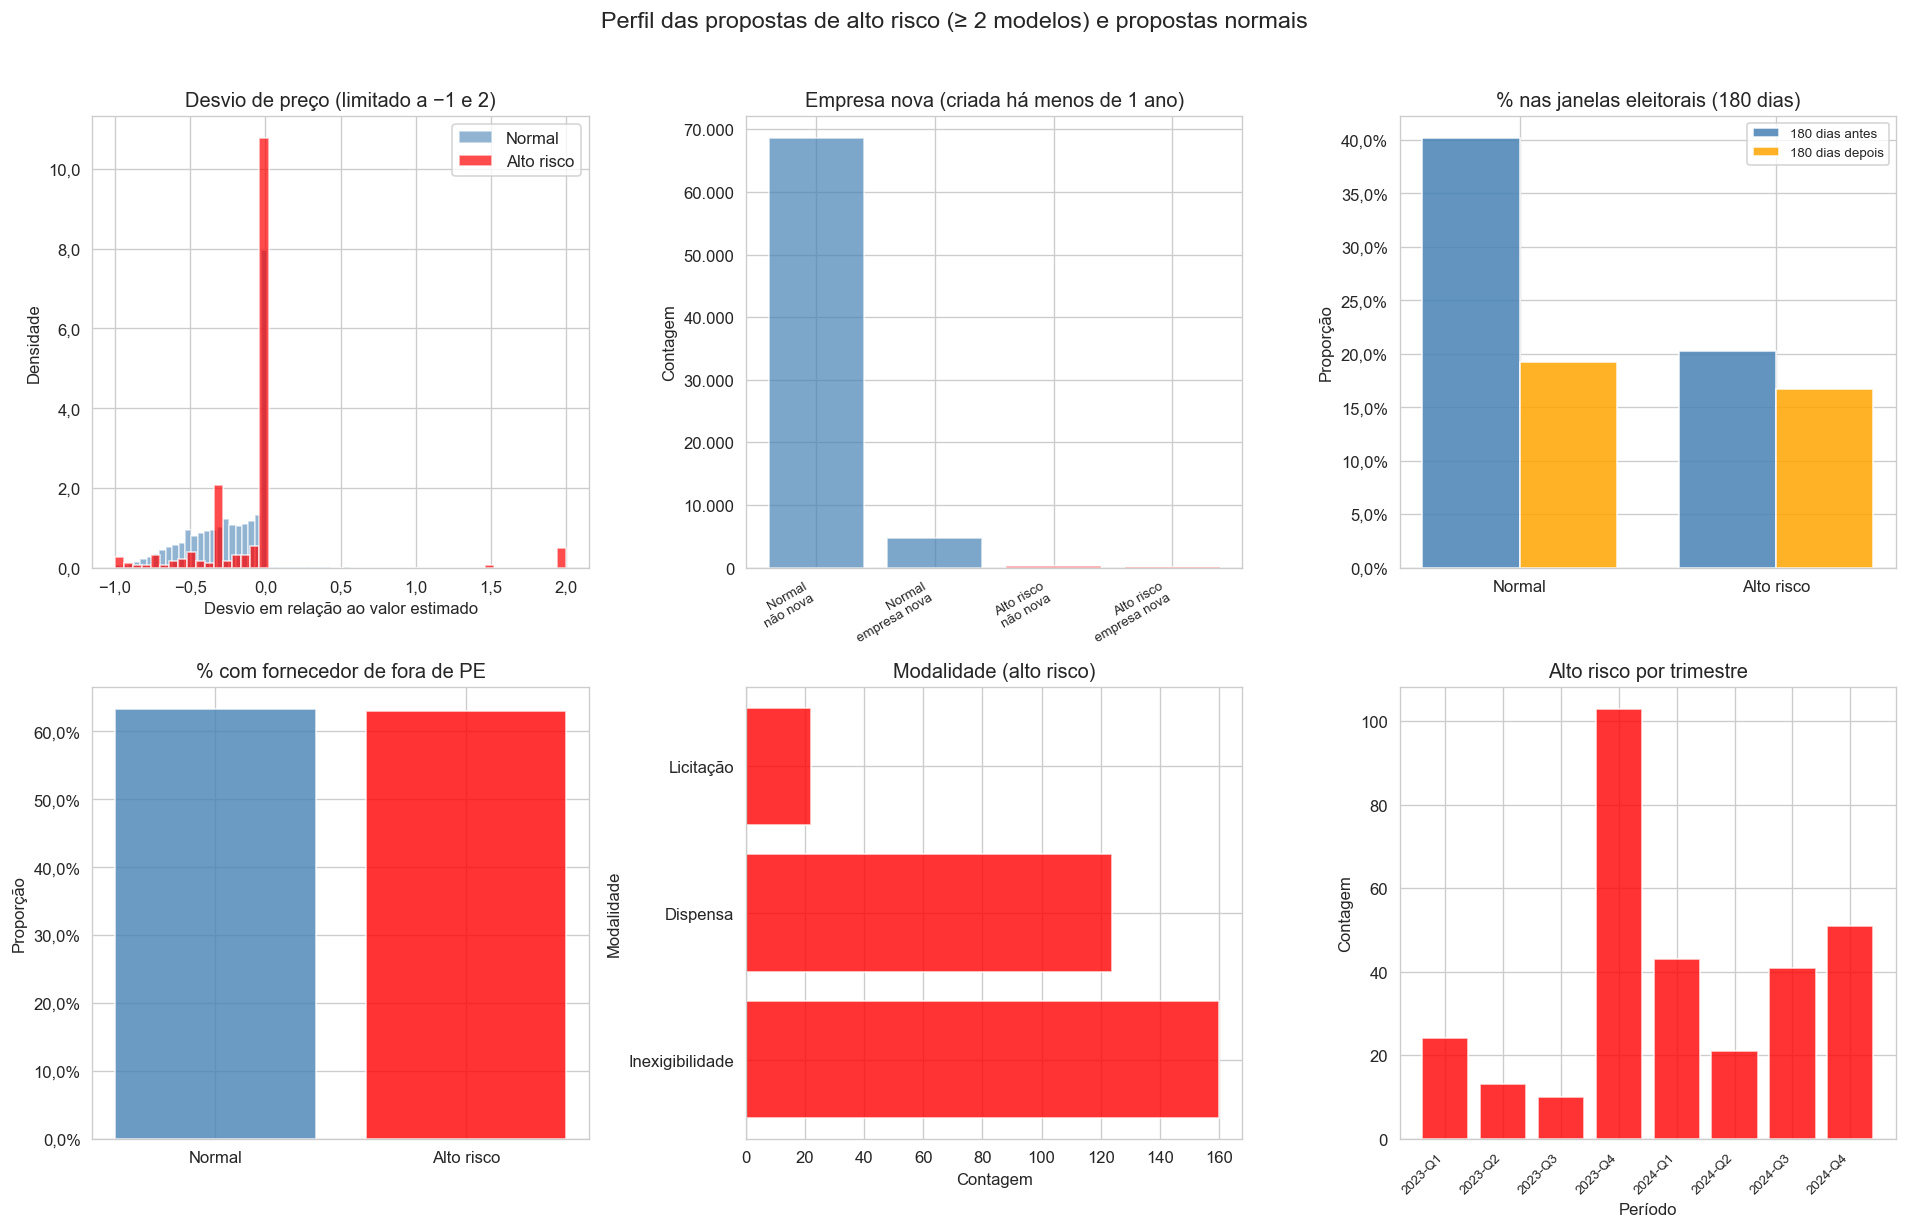

Figura salva em data/output/fig_perfil_alto_risco.png


In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 1. Desvio de preço
axes[0,0].hist(norm['desvio_item_estimado'].clip(-1, 2),
               bins=50, alpha=0.6, label='Normal', color='steelblue', density=True)
axes[0,0].hist(alto['desvio_item_estimado'].clip(-1, 2),
               bins=50, alpha=0.7, label='Alto risco', color='red', density=True)
axes[0,0].set_title('Desvio de preço (limitado a \u22121 e 2)')
axes[0,0].set_xlabel('Desvio em relação ao valor estimado')
axes[0,0].set_ylabel('Densidade')
axes[0,0].legend()
fmt_eixo(axes[0,0], 'x', 1)
fmt_eixo(axes[0,0], 'y', 1)

# 2. Empresa nova
for group, lbl, color in [(norm, 'Normal', 'steelblue'), (alto, 'Alto risco', 'red')]:
    axes[0,1].bar([lbl + '\nnão nova', lbl + '\nempresa nova'],
                  [(group['empresa_nova'] == 0).sum(), (group['empresa_nova'] == 1).sum()],
                  color=color, alpha=0.7)
axes[0,1].set_title('Empresa nova (criada há menos de 1 ano)')
axes[0,1].set_ylabel('Contagem')
fmt_eixo(axes[0,1], 'y', 0)
plt.setp(axes[0,1].get_xticklabels(), rotation=30, ha='right', fontsize=8)

# 3. Janelas eleitorais (180 dias antes e depois da eleição)
x = np.arange(2); w = 0.38
pre_vals = [(norm['pre_eleitoral_180d'] == 1).mean(), (alto['pre_eleitoral_180d'] == 1).mean()]
pos_vals = [(norm['pos_eleitoral_180d'] == 1).mean(), (alto['pos_eleitoral_180d'] == 1).mean()]
axes[0,2].bar(x - w/2, pre_vals, w, label='180 dias antes', color='steelblue', alpha=0.85)
axes[0,2].bar(x + w/2, pos_vals, w, label='180 dias depois', color='orange', alpha=0.85)
axes[0,2].set_xticks(x)
axes[0,2].set_xticklabels(['Normal', 'Alto risco'])
axes[0,2].set_title('% nas janelas eleitorais (180 dias)')
axes[0,2].set_ylabel('Proporção')
axes[0,2].legend(fontsize=8)
fmt_eixo(axes[0,2], 'y', 1, pct=True)

# 4. Fornecedor fora de PE
fpe_norm = (norm['fornecedor_fora_pe'] == 1).mean()
fpe_alto = (alto['fornecedor_fora_pe'] == 1).mean()
axes[1,0].bar(['Normal', 'Alto risco'], [fpe_norm, fpe_alto],
              color=['steelblue', 'red'], alpha=0.8)
axes[1,0].set_title('% com fornecedor de fora de PE')
axes[1,0].set_ylabel('Proporção')
fmt_eixo(axes[1,0], 'y', 1, pct=True)

# 5. Modalidade
mod_alto = alto['modalidade'].value_counts()
axes[1,1].barh(mod_alto.index, mod_alto.values, color='red', alpha=0.8)
axes[1,1].set_title('Modalidade (alto risco)')
axes[1,1].set_xlabel('Contagem')
axes[1,1].set_ylabel('Modalidade')
fmt_eixo(axes[1,1], 'x', 0)

# 6. Distribuição temporal (votos ≥2 por trimestre)
alto_trim = alto.groupby(['ano', 'trimestre']).size().reset_index(name='n')
alto_trim['periodo'] = alto_trim['ano'].astype(str) + '-Q' + alto_trim['trimestre'].astype(str)
axes[1,2].bar(alto_trim['periodo'], alto_trim['n'], color='red', alpha=0.8)
axes[1,2].set_title('Alto risco por trimestre')
axes[1,2].set_xlabel('Período')
axes[1,2].set_ylabel('Contagem')
fmt_eixo(axes[1,2], 'y', 0)
plt.setp(axes[1,2].get_xticklabels(), rotation=45, ha='right', fontsize=8)

plt.suptitle('Perfil das propostas de alto risco (≥ 2 modelos) e propostas normais', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('data/output/fig_perfil_alto_risco.png', bbox_inches='tight')
plt.savefig('figuras_tcc/image4.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figura salva em data/output/fig_perfil_alto_risco.png')

---
### 7. Top-20 da Tabela de Risco

In [24]:
top20_ids = df_ranking.head(20)[['posicao_risco', 'orgaoEntidadeCnpj', 'cnpj_forn_norm',
                                  'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem',
                                  'votos', 'score_combinado']].copy()

top20_completo = top20_ids.merge(
    df_perfil[['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem',
               'cnpj_forn_norm', 'desvio_item_estimado', 'modalidade',
               'empresa_nova', 'fornecedor_fora_pe', 'pre_eleitoral_180d',
               'dias_desde_eleicao', 'idade_empresa_anos']],
    on=['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
        'numeroItem', 'cnpj_forn_norm'],
    how='left'
)

print('=== Top 20 Propostas de Maior Risco ===')
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 200)
top20_completo

=== Top 20 Propostas de Maior Risco ===


,posicao_risco,orgaoEntidadeCnpj,cnpj_forn_norm,anoCompraPncp,sequencialCompraPncp,numeroItem,votos,score_combinado,desvio_item_estimado,modalidade,empresa_nova,fornecedor_fora_pe,pre_eleitoral_180d,dias_desde_eleicao,idade_empresa_anos
0,1,10571982000125,52105018000151,2023,321,1,2,0.588897,-0.439577,Dispensa,1,1,0,-306,0.246407
1,2,394502000144,52934421000193,2024,2623,2,2,0.582513,10.473684,Dispensa,1,1,1,-178,0.391513
2,3,394452000103,7199135000177,2023,9953,95,2,0.562507,92.750000,Licitação,0,0,0,-384,18.642026
3,4,24416174000106,51026267000199,2024,20,3,2,0.559124,-0.452723,Dispensa,1,1,0,-240,0.659822
4,5,24416174000106,51026267000199,2024,20,2,2,0.557141,-0.196787,Dispensa,1,1,0,-240,0.659822
5,6,394452000103,29868059000188,2023,9953,73,2,0.551349,89.476190,Licitação,0,0,0,-384,5.533196
6,7,394452000103,207275000109,2023,12887,43,2,0.545945,8.065657,Licitação,0,0,0,-328,29.138946
7,8,9773169000159,8961997000158,2023,8,1,2,0.541177,0.000000,Dispensa,0,0,0,-340,38.891170
8,9,33781055000135,50290552000150,2024,363,1,2,0.540661,-0.753920,Dispensa,1,0,1,-180,0.993840
9,9,33781055000135,50290552000150,2024,363,1,2,0.540661,-0.753920,Dispensa,1,0,1,-180,0.993840


---
### 8. Sensibilidade das propostas prioritárias ao limiar (0,5%, 1% e 2%)

O número de propostas de alto risco (>= 2 votos) depende dos limiares que atribuem os votos: `contamination` no Isolation Forest e no LOF, e `nu` no One-Class SVM. Esta seção refaz a atribuição de votos com 0,5%, 1% (adotado) e 2% e mede se a tabela é estável.

**Como cada modelo reage ao limiar:**
- **Isolation Forest e LOF:** os escores não mudam, só o ponto de corte (as árvores e as densidades são as mesmas). Por isso os conjuntos sinalizados são **aninhados**: tudo o que é sinalizado a 0,5% também é sinalizado a 1% e a 2%.
- **One-Class SVM:** `nu` altera a fronteira, então o modelo é **reajustado** e o conjunto sinalizado não é necessariamente aninhado; além disso, a fração efetivamente sinalizada pode diferir do `nu` nominal (seção 2.6).

A ordem das propostas usa a mesma regra do ranking (votos e, no desempate, o escore combinado da seção 5, recalculado com o escore do OCSVM de cada limiar).

In [25]:
TAUS = [0.005, 0.01, 0.02]
Xf = df_feat[feature_cols]

# Isolation Forest: as árvores são as mesmas; contamination só define o limiar (percentil dos escores de treino)
ss_if = iso_forest.score_samples(Xf)                       # menor = mais anômalo
def flag_if(tau): return ss_if < np.percentile(ss_if, 100 * tau)

# LOF: escores já calculados (vetores únicos); o limiar é o quantil sobre as propostas
def flag_lof(tau): return lof_scores >= np.quantile(lof_scores, 1 - tau)

assert (flag_if(CONTAMINATION) == (df_feat['if_label'] == -1).to_numpy()).all(), 'limiar do IF não reproduz o da rodada'
assert (flag_lof(CONTAMINATION) == (df_feat['lof_label'] == -1).to_numpy()).all(), 'limiar do LOF não reproduz o da rodada'

# OCSVM: reajusta com nu = tau (para tau = 1% reaproveita o ajuste da rodada)
f_ocsvm = {}
for tau in TAUS:
    if tau == CONTAMINATION:
        f_ocsvm[tau] = df_feat['ocsvm_score'].to_numpy()
    else:
        f_ocsvm[tau] = OneClassSVM(kernel='rbf', nu=tau, gamma='scale').fit(X_scaled).decision_function(X_scaled)

res = {}
for tau in TAUS:
    fl = {'IF': flag_if(tau), 'LOF': flag_lof(tau), 'OCSVM': f_ocsvm[tau] < 0}
    v = sum(x.astype(int) for x in fl.values())
    c = np.mean([minmax(-ss_if), minmax(np.log(s_lof)), minmax(-f_ocsvm[tau])], axis=0)
    ordem = np.lexsort((-c, -v)); pos = np.empty(len(c), dtype=int); pos[ordem] = np.arange(1, len(c) + 1)
    res[tau] = {'flags': fl, 'votos': v, 'alto': v >= 2, 'pos': pos}

linhas = []
for tau in TAUS:
    r = res[tau]; fl = r['flags']
    linhas.append({'Limiar': f'{tau:.1%}'.replace('.', ','), 'IF': int(fl['IF'].sum()), 'LOF': int(fl['LOF'].sum()), 'OCSVM (efetivo)': int(fl['OCSVM'].sum()),
                   '1 voto': int((r['votos'] == 1).sum()), 'Alto risco (>= 2 votos)': int(r['alto'].sum()), '3 votos': int((r['votos'] == 3).sum())})
sens = pd.DataFrame(linhas).set_index('Limiar')
print('=== Propostas sinalizadas e votos por limiar ===')
print(sens.to_string())

pares = [(0.005, 0.01), (0.01, 0.02), (0.005, 0.02)]
est = []
for a, b in pares:
    Ha, Hb = res[a]['alto'], res[b]['alto']; comuns = Ha & Hb
    linha = {'Comparação': f'{a:.1%} × {b:.1%}'.replace('.', ','), 'Alto risco A': int(Ha.sum()), 'Alto risco B': int(Hb.sum()), 'Em comum': int(comuns.sum()),
             'Jaccard': round(comuns.sum() / (Ha | Hb).sum(), 3), '% de A contida em B': round(comuns.sum() / Ha.sum() * 100, 1) if Ha.sum() else np.nan}
    if comuns.sum() > 2:
        linha['Spearman da posição (em comum)'] = round(spearmanr(res[a]['pos'][comuns], res[b]['pos'][comuns])[0], 3)
    for n in (20, 50):
        linha[f'Top-{n} em comum'] = int(((res[a]['pos'] <= n) & (res[b]['pos'] <= n)).sum())
    est.append(linha)
estab = pd.DataFrame(est).set_index('Comparação')
nucleo = res[0.005]['alto'] & res[0.01]['alto'] & res[0.02]['alto']
print('\n=== Estabilidade do conjunto de alto risco entre limiares ===')
print(estab.T.to_string())
print(f'\nNúcleo estável (alto risco nos três limiares): {int(nucleo.sum())} propostas '
      f'({nucleo.sum() / res[0.01]["alto"].sum():.0%} do alto risco a 1%)')
print('Aninhamento dos conjuntos de IF e LOF (0,5% ⊂ 1% ⊂ 2%):',
      all((res[a]['flags'][m] & ~res[b]['flags'][m]).sum() == 0 for m in ('IF', 'LOF') for a, b in ((0.005, 0.01), (0.01, 0.02))))
print('Aninhamento do OCSVM (0,5% ⊂ 1% ⊂ 2%):',
      all((res[a]['flags']['OCSVM'] & ~res[b]['flags']['OCSVM']).sum() == 0 for a, b in ((0.005, 0.01), (0.01, 0.02))))

sens.to_csv('data/output/sensibilidade_limiar.csv')
estab.to_csv('data/output/sensibilidade_limiar_estabilidade.csv')
print('\nSalvos: data/output/sensibilidade_limiar.csv e data/output/sensibilidade_limiar_estabilidade.csv')


=== Propostas sinalizadas e votos por limiar ===
          IF   LOF  OCSVM (efetivo)  1 voto  Alto risco (>= 2 votos)  3 votos
Limiar                                                                       
0,5%     372   381              663    1090                      163        0
1,0%     743   755              816    1702                      306        0
2,0%    1502  1510             2183    3697                      748        2

=== Estabilidade do conjunto de alto risco entre limiares ===
Comparação                      0,5% × 1,0%  1,0% × 2,0%  0,5% × 2,0%
Alto risco A                        163.000      306.000      163.000
Alto risco B                        306.000      748.000      748.000
Em comum                            119.000      306.000      163.000
Jaccard                               0.340        0.409        0.218
% de A contida em B                  73.000      100.000      100.000
Spearman da posição (em comum)        0.732        0.930        0.691
Top-20 e

**Leitura (rodada atual).**
- **O número de propostas prioritárias depende do limiar**: 163, 306 e 748 propostas de alto risco a 0,5%, 1% e 2%. O total não é uma propriedade estável dos dados.
- **O conjunto é estável na direção do aninhamento**: as 306 propostas de 1% estão todas contidas nas 748 de 2%; 73% das 163 de 0,5% (119) permanecem a 1%, e todas permanecem a 2%. Fica um **núcleo de 119 propostas** que são de alto risco nos três limiares (39% do conjunto de 1%).
  A contenção não é de 100% entre 0,5% e 1% porque o OCSVM é reajustado com outro `nu` e sua fronteira muda.
- **A ordem muda moderadamente**: entre 0,5% e 1%, a correlação de Spearman das posições é 0,73 e 13 das 20 primeiras coincidem; entre 1% e 2%, 0,93 e 17 de 20. O Jaccard é baixo (0,34 e 0,41) sobretudo porque os conjuntos têm tamanhos muito diferentes; a medida mais informativa é a contenção.
- **Limitação:** a lista de 306 é um recorte, não um conjunto natural. Convém apresentá-la como a faixa de maior prioridade dentro de uma ordenação contínua (a posição no ranking), e o núcleo de 119 como as propostas robustas ao limiar.

---
### 9. Tabela de hiperparâmetros

Reúne em um só lugar os parâmetros dos três modelos, a normalização do escore combinado e a regra de votos, com a justificativa de cada escolha e o pré-processamento aplicado. Os valores são lidos dos próprios modelos ajustados nesta rodada.
Fica salva em `data/output/hiperparametros_modelos.csv` para uso na seção de metodologia.

In [26]:
linhas = [
    ('Isolation Forest', 'n_estimators', iso_forest.n_estimators, 'Equilíbrio entre estabilidade e custo computacional.', 'nenhum (os cortes são feitos variável a variável)'),
    ('Isolation Forest', 'max_samples', iso_forest.max_samples, 'Padrão do scikit-learn; eficiente em bases grandes.', ''),
    ('Isolation Forest', 'contamination', CONTAMINATION, '1% esperado de anomalias, definição conservadora (alinhada a Araújo et al., 2024). Só define o limiar de corte; sensibilidade na seção 8.', ''),
    ('Isolation Forest', 'random_state', RANDOM_STATE, 'Reprodutibilidade dos resultados.', ''),
    ('LOF', 'n_neighbors', lof.n_neighbors, 'Valores menores geravam avisos de duplicatas. Não elimina o problema (40 vetores têm mais de 50 cópias): por isso o LOF é ajustado só nos vetores únicos (seção 2.5). Sensibilidade a n_neighbors não avaliada.', 'StandardScaler em todas as colunas (seção 2.4)'),
    ('LOF', 'contamination', CONTAMINATION, 'Mesma proporção do IF, por consistência; aplicada como limiar sobre as propostas (não sobre os vetores únicos).', ''),
    ('LOF', 'escore', 'ln(LOF) no escore combinado', 'LOF = -negative_outlier_factor_ (razão de densidades, cauda extrema); log antes do min-max (seção 5).', ''),
    ('One-Class SVM', 'kernel', ocsvm.kernel, 'Captura relações não lineares entre as variáveis.', 'StandardScaler em todas as colunas (sem padronização, variáveis de maior escala dominam o kernel)'),
    ('One-Class SVM', 'nu', ocsvm.nu, 'Limite superior da fração de pontos fora da fronteira e inferior da fração de vetores de suporte; não fixa a proporção sinalizada (seção 2.6).', ''),
    ('One-Class SVM', 'gamma', f"scale (= {ocsvm._gamma:.4f})", '1 / (n_variáveis × variância dos dados), calculado a partir da própria base.', ''),
    ('One-Class SVM', 'tol', ocsvm.tol, 'Padrão do scikit-learn; apertar a tolerância não elimina o efeito das duplicatas na fronteira (seção 2.6).', ''),
    ('Escore combinado', 'normalização', 'min-max; ln(LOF)', 'Média simples de três escores orientados (maior = mais anômalo); ver equação na seção 5 e comparação na 5.1.', ''),
    ('Votos', 'alto risco', '>= 2 votos', 'Proposta sinalizada por pelo menos dois dos três modelos; sensibilidade ao limiar na seção 8.', ''),
]
hiper = pd.DataFrame(linhas, columns=['Modelo', 'Parâmetro', 'Valor', 'Justificativa', 'Pré-processamento'])
print(hiper.to_string(index=False, max_colwidth=70))
hiper.to_csv('data/output/hiperparametros_modelos.csv', index=False)
print('\nSalvo em data/output/hiperparametros_modelos.csv')


          Modelo     Parâmetro                       Valor                                                          Justificativa                                                      Pré-processamento
Isolation Forest  n_estimators                         100                   Equilíbrio entre estabilidade e custo computacional.                      nenhum (os cortes são feitos variável a variável)
Isolation Forest   max_samples                         256                    Padrão do scikit-learn; eficiente em bases grandes.                                                                       
Isolation Forest contamination                        0.01 1% esperado de anomalias, definição conservadora (alinhada a Araújo...                                                                       
Isolation Forest  random_state                          42                                      Reprodutibilidade dos resultados.                                                                   